In [17]:
import pandas as pd                      # table (DataFrame) saathi
from ucimlrepo import fetch_ucirepo      # UCI repository madhun dataset ghenyasaathi


# cleaned data direct file madhun vachto, UCI download parat nahi karaycha
df_clean = pd.read_csv("../data/processed/ckd_clean.csv")

ckd = fetch_ucirepo(id=336)              # CKD dataset cha UCI id 336 aahe

X = ckd.data.features                    # input columns (age, bp, hemo...)
y = ckd.data.targets                     # target column (ckd / notckd)

df = pd.concat([X, y], axis=1)           # donhi jodun ek table

df.to_csv("../data/raw/ckd_raw.csv", index=False)   # original data save, nantar kadhich edit karaycha nahi

print(df.shape)                          # (rows, columns)

(400, 25)


In [4]:
df.head()

,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    str    
 6   pc      335 non-null    str    
 7   pcc     396 non-null    str    
 8   ba      396 non-null    str    
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    str    
 19  dm      398 non-null    str    
 20  cad     398 non-null    str    
 21  appet   399 non-null    str    
 22  pe      399 n

In [6]:
df.isnull().sum().sort_values(ascending=False)   # kontya column madhe kiti missing, jast pasun kami

rbc      152
rbcc     131
wbcc     106
pot       88
sod       87
pcv       71
pc        65
hemo      52
su        49
sg        47
al        46
bgr       44
bu        19
sc        17
bp        12
age        9
pcc        4
ba         4
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
class      0
dtype: int64

In [7]:
df["class"].value_counts()    # kiti ckd, kiti notckd

class
ckd       248
notckd    150
ckd\t       2
Name: count, dtype: int64

In [8]:
# Target madhe kontya unique values aahet te baghto
print(df["class"].unique())          # ajeeb value (jasa 'ckd\t') distil ka?

# Prattek column cha data type baghto
print(df.dtypes)                     # numeric columns 'object' astil tar problem aahe

<StringArray>
['ckd', 'ckd\t', 'notckd']
Length: 3, dtype: str
age      float64
bp       float64
sg       float64
al       float64
su       float64
rbc          str
pc           str
pcc          str
ba           str
bgr      float64
bu       float64
sc       float64
sod      float64
pot      float64
hemo     float64
pcv      float64
wbcc     float64
rbcc     float64
htn          str
dm           str
cad          str
appet        str
pe           str
ane          str
class        str
dtype: object


In [9]:
# Categorical columns madhe kontya values aahet te baghto
cat_cols = df.select_dtypes(include="object").columns   # text type che columns
for c in cat_cols:                                       # prattek column saathi
    print(c, df[c].unique())                             # tyatle unique values print kar

rbc <StringArray>
[nan, 'normal', 'abnormal']
Length: 3, dtype: str
pc <StringArray>
['normal', 'abnormal', nan]
Length: 3, dtype: str
pcc <StringArray>
['notpresent', 'present', nan]
Length: 3, dtype: str
ba <StringArray>
['notpresent', 'present', nan]
Length: 3, dtype: str
htn <StringArray>
['yes', 'no', nan]
Length: 3, dtype: str
dm <StringArray>
['yes', 'no', '\tno', nan]
Length: 4, dtype: str
cad <StringArray>
['no', 'yes', nan]
Length: 3, dtype: str
appet <StringArray>
['good', 'poor', nan]
Length: 3, dtype: str
pe <StringArray>
['no', 'yes', nan]
Length: 3, dtype: str
ane <StringArray>
['no', 'yes', nan]
Length: 3, dtype: str
class <StringArray>
['ckd', 'ckd\t', 'notckd']
Length: 3, dtype: str


C:\Users\bhumi\AppData\Local\Temp\ipykernel_16216\3241546171.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns   # text type che columns


In [10]:
# original df chi copy gheto, mhanje raw data surakshit rahto
df_clean = df.copy()

# sagle text columns shodhto (object ani string donhi type)
text_cols = df_clean.select_dtypes(include=["object", "string"]).columns

# prattek text column madhun aaju-baju che space/tab kaadhto
for c in text_cols:
    df_clean[c] = df_clean[c].str.strip()   # missing values (NaN) tashach rahtat

In [11]:
# aata class madhe fakt 2 values pahijet
print(df_clean["class"].unique())

# dm madhla '\tno' gela pahije
print(df_clean["dm"].unique())

# class che count parat tapasto
print(df_clean["class"].value_counts())

<StringArray>
['ckd', 'notckd']
Length: 2, dtype: str
<StringArray>
['yes', 'no', nan]
Length: 3, dtype: str
class
ckd       250
notckd    150
Name: count, dtype: int64


In [12]:
# cleaned data processed folder madhe save karto, raw folder la hat nahi lavla
df_clean.to_csv("../data/processed/ckd_clean.csv", index=False)

In [13]:
import matplotlib.pyplot as plt      # graphs saathi basic library
import seaborn as sns                # matplotlib var sundar graphs
import os

# graphs save karnyasaathi folder (aadhi asel tar error nahi)
os.makedirs("../reports/figures", exist_ok=True)

sns.set_theme(style="whitegrid")     # graphs cha look clean thevto

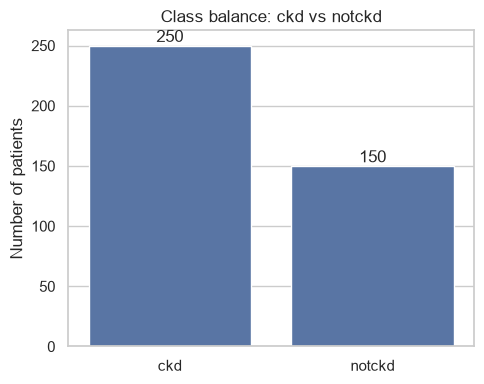

In [14]:
# ckd ani notckd che count
counts = df_clean["class"].value_counts()

plt.figure(figsize=(5, 4))
sns.barplot(x=counts.index, y=counts.values)   # bar graph
plt.title("Class balance: ckd vs notckd")
plt.ylabel("Number of patients")
plt.xlabel("")

# prattek bar var number lihito
for i, v in enumerate(counts.values):
    plt.text(i, v + 3, str(v), ha="center")

plt.tight_layout()
plt.savefig("../reports/figures/class_balance.png", dpi=150)   # file save
plt.show()

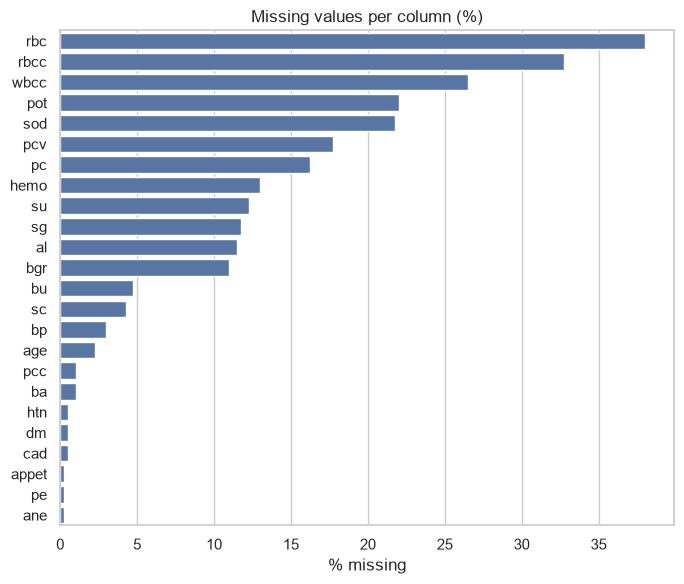

rbc      38.0
rbcc     32.8
wbcc     26.5
pot      22.0
sod      21.8
pcv      17.8
pc       16.2
hemo     13.0
su       12.2
sg       11.8
al       11.5
bgr      11.0
bu        4.8
sc        4.2
bp        3.0
age       2.2
pcc       1.0
ba        1.0
htn       0.5
dm        0.5
cad       0.5
appet     0.2
pe        0.2
ane       0.2
dtype: float64


In [15]:
# kiti % values missing aahet prattek column madhe
missing_pct = (df_clean.isnull().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]     # fakt jyat missing aahe te

plt.figure(figsize=(7, 6))
sns.barplot(x=missing_pct.values, y=missing_pct.index)   # horizontal bars
plt.title("Missing values per column (%)")
plt.xlabel("% missing")
plt.ylabel("")
plt.tight_layout()
plt.savefig("../reports/figures/missing_values.png", dpi=150)
plt.show()

print(missing_pct.round(1))      # exact numbers pan baghto

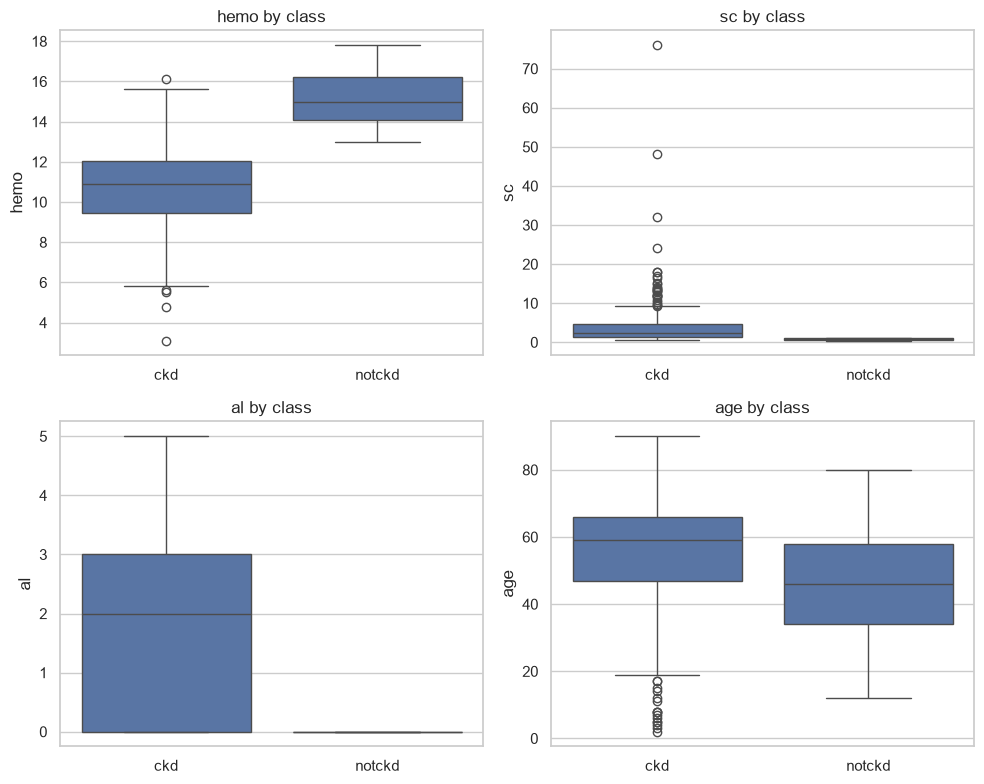

In [18]:
cols = ["hemo", "sc", "al", "age"]

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()                    # 2D grid la simple list banvto

for ax, c in zip(axes, cols):
    # prattek class (ckd / notckd) saathi vegla box
    sns.boxplot(data=df_clean, x="class", y=c, ax=ax)
    ax.set_title(f"{c} by class")        # graph cha title
    ax.set_xlabel("")

plt.tight_layout()
plt.savefig("../reports/figures/numeric_by_class.png", dpi=150)
plt.show()

In [19]:
# prattek class madhe median kiti aahe (median mhanje madhla value, outliers cha parinaam kami)
df_clean.groupby("class")[cols].median()

,hemo,sc,al,age
class,,,,
ckd,10.9,2.25,2.0,59.0
notckd,15.0,0.90,0.0,46.0
